## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**. 
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [74]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [56]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')#completa el código

In [4]:
traffic.head(5) # mostrar las primeras 5 filas de traffic

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [57]:
eco.head(5)# mostrar las primeras 5 filas de eco

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [58]:
# Examinar la estructura de traffic
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTC` son de tipo ...
- object requieren conversión a DATETIME

In [59]:
# Examinar la estructura de eco
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, ...
- Son tipo OBJECT, toca realizar una conversión a tipo FLOAT

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [60]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
traffic = traffic.rename(columns={'Country':'country','UpdateTimeUTC':'update_time_utc'})
# verificar cambios
traffic.columns

Index(['country', 'City', 'update_time_utc', 'JamsDelay', 'TrafficIndexLive',
       'JamsLengthInKms', 'JamsCount', 'TrafficIndexWeekAgo',
       'UpdateTimeUTCWeekAgo', 'TravelTimeLivePer10KmsMins',
       'TravelTimeHistoricPer10KmsMins', 'MinsDelay'],
      dtype='object')

In [61]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco = eco.rename(columns={'Country':'country'})
# verificar cambios
eco.columns

Index(['Year', 'City', 'country', 'City GDP/capita', 'Unemployment %',
       'PM2.5 (μg/m³)', 'Population (M)'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [62]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors="coerce", utc = True)#tu código aquí
traffic['UpdateTimeUTCWeekAgo'] = pd.to_datetime(traffic['UpdateTimeUTCWeekAgo'], errors="coerce", utc = True)#tu código aquí

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype              
---  ------                          --------------    -----              
 0   country                         1004464 non-null  object             
 1   City                            1004464 non-null  object             
 2   update_time_utc                 1004464 non-null  datetime64[ns, UTC]
 3   JamsDelay                       1004464 non-null  float64            
 4   TrafficIndexLive                1004464 non-null  float64            
 5   JamsLengthInKms                 1004464 non-null  float64            
 6   JamsCount                       1004464 non-null  float64            
 7   TrafficIndexWeekAgo             1004464 non-null  float64            
 8   UpdateTimeUTCWeekAgo            1004464 non-null  datetime64[ns, UTC]
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64

In [63]:
# Limpia separadores y convierte columnas numéricas en eco
# eco['city_gdp_capita'] = ....astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['City GDP/capita'] = eco['City GDP/capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
# eco['unemployment_pct'] = ...
eco['Unemployment %'] = eco['Unemployment %'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
# eco['population_m'] = ...
eco['Population (M)'] = eco['Population (M)'].astype(str).str.replace(',', '.').astype(float)
# Calcula la población total en unidades absolutas (Multiplica * 1000000)
# eco['population'] = ...
eco['population'] = eco['Population (M)']*1000000
# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             30 non-null     int64  
 1   City             30 non-null     object 
 2   country          30 non-null     object 
 3   City GDP/capita  30 non-null     float64
 4   Unemployment %   30 non-null     float64
 5   PM2.5 (μg/m³)    30 non-null     object 
 6   Population (M)   30 non-null     float64
 7   population       30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,Year,City,country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M),population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [64]:
# Extraer el año de las fechas en update_time_utc
# traffic['year'] = ...
traffic['year'] = traffic['update_time_utc'].dt.year
# Verificar cambio
traffic.head(10)

,country,City,update_time_utc,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001000+00:00,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30+00:00,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00+00:00,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001000+00:00,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30+00:00,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30+00:00,8.196278,8.196510,-0.000232,2025
3,ARE,abu-dhabi,2025-01-13 01:46:30.001000+00:00,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30+00:00,7.723808,7.899046,-0.175238,2025
4,ARE,abu-dhabi,2025-01-13 00:01:30+00:00,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30+00:00,8.336363,8.604379,-0.268016,2025
5,ARE,abu-dhabi,2025-01-12 23:01:30+00:00,5.6,2.0,0.4,2.0,1.0,2025-01-05 23:01:30.001000+00:00,8.309699,8.515687,-0.205988,2025
6,ARE,abu-dhabi,2025-01-12 22:31:30+00:00,5.0,2.0,0.9,1.0,1.0,2025-01-05 22:01:30.001000+00:00,8.337259,8.536889,-0.199630,2025
7,ARE,abu-dhabi,2025-01-12 21:01:30.001000+00:00,10.2,3.0,1.5,5.0,3.0,2025-01-05 21:01:00+00:00,8.430088,8.590590,-0.160502,2025
8,ARE,abu-dhabi,2025-01-12 20:01:30+00:00,40.9,13.0,9.9,16.0,5.0,2025-01-05 20:01:00+00:00,9.126345,8.656094,0.470252,2025
9,ARE,abu-dhabi,2025-01-12 19:16:30+00:00,197.9,17.0,20.0,37.0,7.0,2025-01-05 19:01:00+00:00,9.716549,9.014157,0.702391,2025


In [65]:

# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
# traffic_2024 = traffic[...].copy()
# eco_2024 = ...
eco_2024 = eco[eco['Year'] == 2024].copy()
# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())

,country,City,update_time_utc,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30+00:00,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001000+00:00,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30+00:00,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30+00:00,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30+00:00,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30+00:00,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001000+00:00,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001000+00:00,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00+00:00,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00+00:00,11.686322,10.008469,1.677853,2024


,Year,City,country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M),population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [66]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = traffic_2024.groupby(['City', 'country', 'year'], as_index=False)[[
    'JamsDelay', 
    'TrafficIndexLive', 
    'JamsLengthInKms', 
    'JamsCount', 
    'MinsDelay', 
    'TravelTimeLivePer10KmsMins', 
    'TravelTimeHistoricPer10KmsMins'
]].mean() # tu código aqui

# Mostrar resultado
traffic_city_year_2024.head()

,City,country,year,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,MinsDelay,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [67]:
traffic_city_year_2024.sort_values(["JamsDelay"], ascending=False)# tu código aquí

,City,country,year,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,MinsDelay,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es MEXICO


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


In [68]:
traffic_city_year_2024= traffic_city_year_2024.rename(columns={"country":"Country",
                                            "update_time_utc":"Update_time_utc",
                                           "year":"Year"})
traffic_2024.head(3)
traffic_2024.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 886779 entries, 302 to 1004463
Data columns (total 13 columns):
 #   Column                          Non-Null Count   Dtype              
---  ------                          --------------   -----              
 0   country                         886779 non-null  object             
 1   City                            886779 non-null  object             
 2   update_time_utc                 886779 non-null  datetime64[ns, UTC]
 3   JamsDelay                       886779 non-null  float64            
 4   TrafficIndexLive                886779 non-null  float64            
 5   JamsLengthInKms                 886779 non-null  float64            
 6   JamsCount                       886779 non-null  float64            
 7   TrafficIndexWeekAgo             886779 non-null  float64            
 8   UpdateTimeUTCWeekAgo            886779 non-null  datetime64[ns, UTC]
 9   TravelTimeLivePer10KmsMins      886779 non-null  float64           

In [69]:
eco_2024 = eco_2024.rename(columns={"Unemployment %":"Unemployment",
                                            "population":"Population",
                                           "year":"Year","country":"Country"})
eco_2024.head(3)
eco_2024.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 15 to 29
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             15 non-null     int64  
 1   City             15 non-null     object 
 2   Country          15 non-null     object 
 3   City GDP/capita  15 non-null     float64
 4   Unemployment     15 non-null     float64
 5   PM2.5 (μg/m³)    15 non-null     object 
 6   Population (M)   15 non-null     float64
 7   Population       15 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 1.1+ KB


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [70]:


# Seleccionar columnas clave de tráfico y economía
left_cols = ['City','Country','Year','JamsDelay','TrafficIndexLive',
             'JamsLengthInKms','JamsCount','MinsDelay',
             'TravelTimeLivePer10KmsMins','TravelTimeHistoricPer10KmsMins']

right_cols = ['City','Year','City GDP/capita','Unemployment','PM2.5 (μg/m³)','Population']

# Usar .copy() para crear los dos nuevos datasets reducidos
# traffic_2024_small = traffic_city_year_2024[ ... ].copy()
traffic_2024_small = traffic_city_year_2024.copy() 
# eco_2024_small = ...
eco_2024_small = eco_2024.copy()
# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024, on=['City','Year'], how='inner')# tu código aquí

# Mostrar las primeras 5 filas
merged.head(5) # tu código aquí




,City,Country_x,Year,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,MinsDelay,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,Country_y,City GDP/capita,Unemployment,PM2.5 (μg/m³),Population (M),Population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,Brazil,11124.0,9.5,"16,80",6.1,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,Colombia,11442.0,10.0,"17,60",11.3,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,Brazil,12381.0,8.2,"13,50",3.7,3700000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

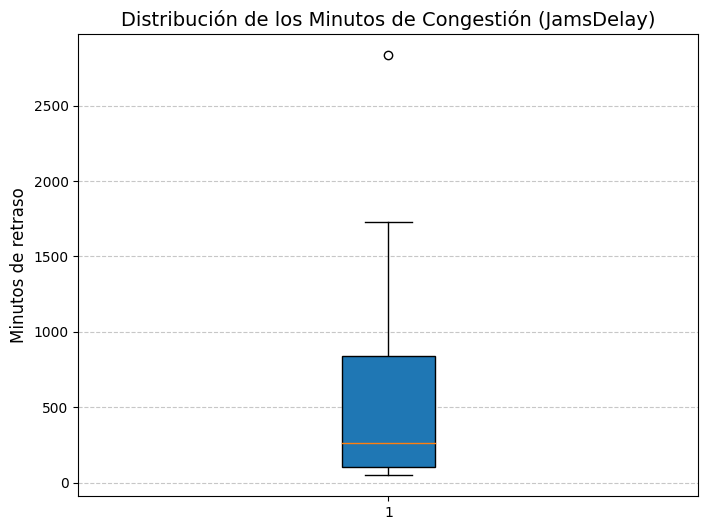

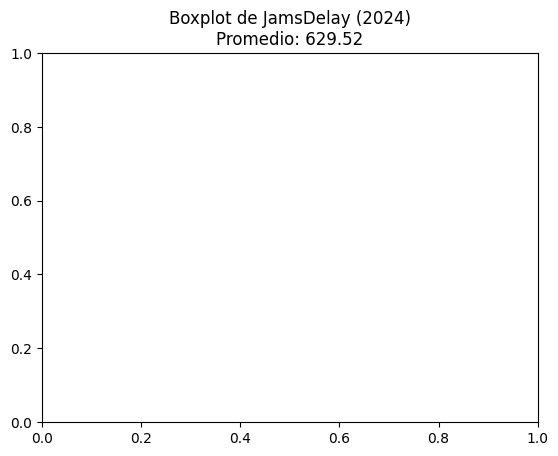

In [71]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
plt.figure(figsize=(8, 6))
plt.boxplot(merged['JamsDelay'].dropna(), patch_artist=True)

# Personalizar el gráfico con títulos y etiquetas
plt.title('Distribución de los Minutos de Congestión (JamsDelay)', fontsize=14)
plt.ylabel('Minutos de retraso', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# crea tu gráfico
plt.show()

# obtener promedio para mostrarlo en título
mean_value = merged['JamsDelay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


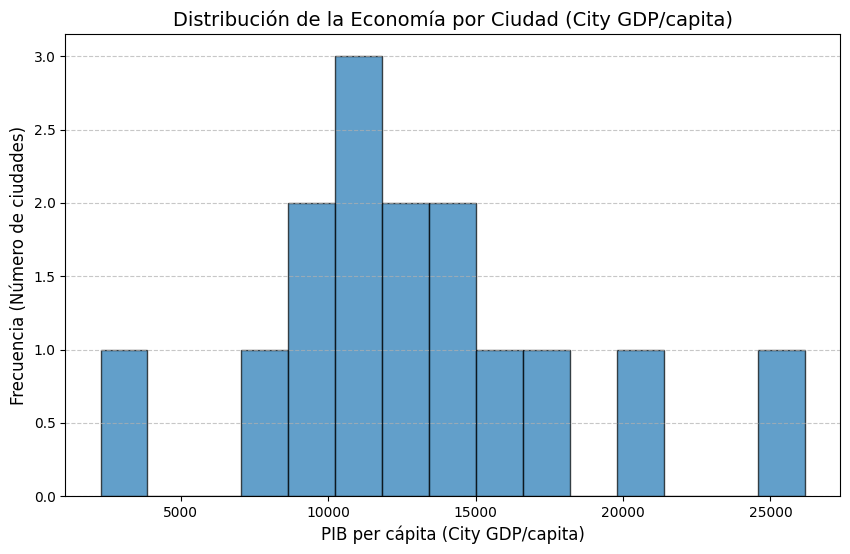

In [72]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.figure(figsize=(10, 6))
plt.hist(merged['City GDP/capita'].dropna(), bins=15, edgecolor='black', alpha=0.7)

# Personalizar el gráfico con títulos y etiquetas
plt.title('Distribución de la Economía por Ciudad (City GDP/capita)', fontsize=14)
plt.xlabel('PIB per cápita (City GDP/capita)', fontsize=12)
plt.ylabel('Frecuencia (Número de ciudades)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)


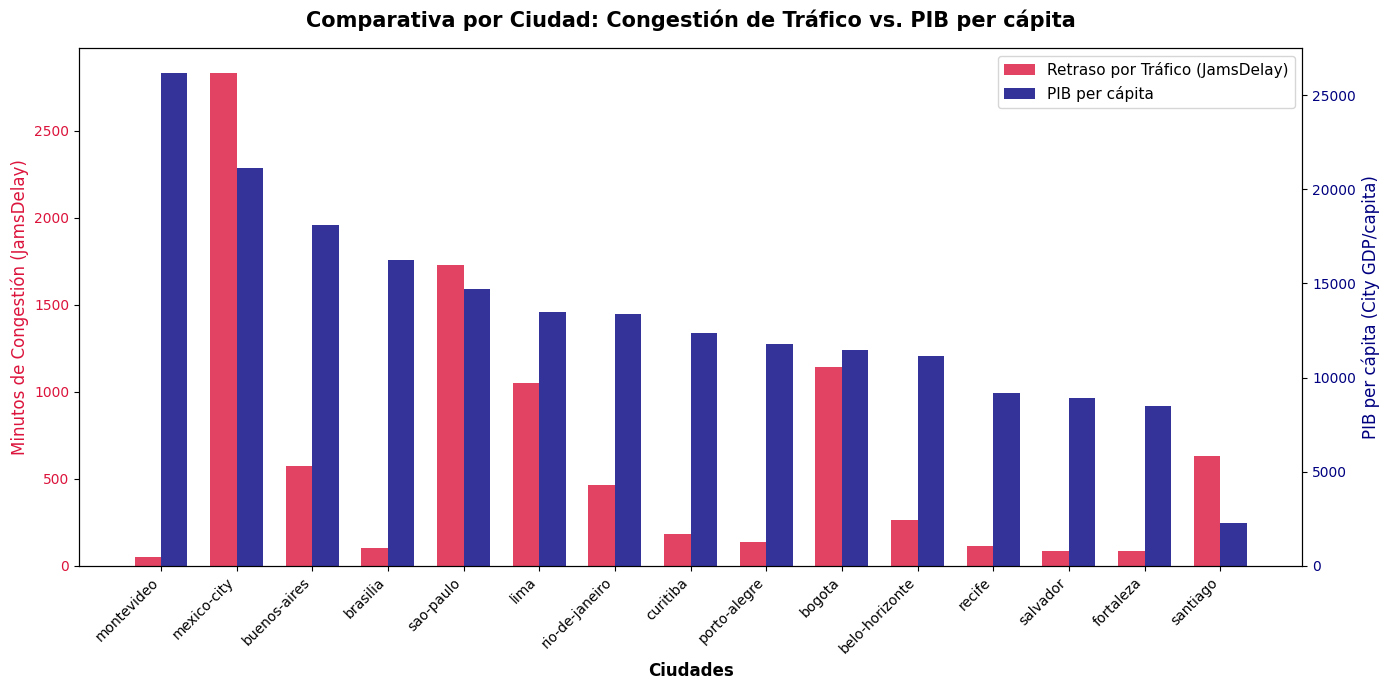

In [75]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
#merged.plot( ... , y=['jams_delay', 'city_gdp_capita'])
df_plot = merged[['City', 'JamsDelay', 'City GDP/capita']].dropna().sort_values(by='City GDP/capita', ascending=False)

# Configurar posiciones de las barras
x = np.arange(len(df_plot['City']))
width = 0.35  # Ancho de las barras

fig, ax1 = plt.subplots(figsize=(14, 7))

# 2. Primera barra: JamsDelay (Eje Y izquierdo)
bar1 = ax1.bar(x - width/2, df_plot['JamsDelay'], width, label='Retraso por Tráfico (JamsDelay)', color='crimson', alpha=0.8)
ax1.set_xlabel('Ciudades', fontsize=12, fontweight='bold')
ax1.set_ylabel('Minutos de Congestión (JamsDelay)', color='crimson', fontsize=12)
ax1.tick_params(axis='y', labelcolor='crimson')

# 3. Crear un segundo eje Y que comparte el mismo eje X
ax2 = ax1.twinx()

# Segunda barra: City GDP/capita (Eje Y derecho)
bar2 = ax2.bar(x + width/2, df_plot['City GDP/capita'], width, label='PIB per cápita', color='navy', alpha=0.8)
ax2.set_ylabel('PIB per cápita (City GDP/capita)', color='navy', fontsize=12)
ax2.tick_params(axis='y', labelcolor='navy')

# 4. Personalizar el diseño del gráfico
plt.title('Comparativa por Ciudad: Congestión de Tráfico vs. PIB per cápita', fontsize=15, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(df_plot['City'], rotation=45, ha='right', fontsize=10)

# Añadir las leyendas combinadas de ambos ejes
lineas_barras = [bar1, bar2]
etiquetas = [b.get_label() for b in lineas_barras]
ax1.legend(lineas_barras, etiquetas, loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios: No, las ciudades con mayor PIB no necesariamente presenta más congestión; de hecho no presenta una relación tan clara solo para algunas pocas ciudades.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [76]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información. 


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto & objetivo:**  
- El análisis busca identificar ciudades donde los problemas de movilidad urbana podrían estar asociados con condiciones económicas desfavorables, para orientar inversiones en infraestructura de transporte que mejoren la productividad y el bienestar de la población.
  
- Se compararon indicadores de congestión vehicular, retrasos y tiempos de viaje con el PIB per cápita y la tasa de desempleo. Es importante distinguir entre una asociación estadística y una relación causal: los datos permiten identificar ciudades prioritarias para investigar, pero no demuestran por sí solos que la congestión reduzca la productividad económica.

**Cobertura de datos:**  
- La base analizada contiene información de 15 ciudades de 7 países Brasil, Colombia, Argentina, Perú, México, Uruguay y Chile correspondiente al año 2024.

**Metodología (alto nivel):**  
- La metodología comprende la revisión de tipos de datos, estandarización de nombres de ciudades y países, verificación de formatos numéricos y revisión de registros atípicos. La integración de movilidad y economía se plantea mediante una unión INNER por ciudad y año, conservando únicamente las observaciones coincidentes en ambas fuentes. Se examinan las distribuciones de las variables, los valores extremos, los gráficos comparativos. La base entregada ya contiene las variables integradas; por tanto, la ejecución original de la unión y la eliminación de duplicados deben verificarse en el proceso de preparación si se requiere documentar que efectivamente se realizaron.

**Hallazgos iniciales:**  
- Ciudad de México registra el mayor valor de Retraso por atascos (2.833,1), seguida de São Paulo (1.729,2), Bogotá (1.141,6) y Lima (1.052,3). Bogotá combina una congestión elevada con un PIB per cápita de 11.442 y un desempleo del 10,0 %. Lima presenta un patrón similar, con un PIB per cápita de 13.472 y desempleo del 6,5 %. Sin embargo, Ciudad de México tiene el mayor retraso registrado y un PIB per cápita de 21.111, lo que evidencia que una congestión alta no implica necesariamente un PIB per cápita bajo. Además, el valor de PIB per cápita de Santiago (2.277) requiere validación, pues podría afectar las comparaciones y los resultados estadísticos.

**Recomendaciones**  
- Se recomienda priorizar un estudio de prefactibilidad de movilidad en Bogotá, seguido de Lima y São Paulo, sin descartar Ciudad de México, que presenta el mayor valor de retraso. Bogotá merece atención por sus indicadores combinados de congestión, desempleo y PIB per cápita; Lima, por sus elevados tiempos de viaje; y São Paulo, por su alto volumen de congestión. Antes de asignar recursos, deben validarse las unidades de las variables, la comparabilidad entre ciudades y los beneficios esperados de cada intervención. La selección definitiva debe considerar también la demanda de transporte público, los corredores críticos, los costos de los proyectos, la reducción esperada de los tiempos de viaje y los beneficios sociales y ambientales.
